In [1]:
!pip install catboost xgboost lightgbm gradio

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (RandomForestRegressor, BaggingRegressor, ExtraTreesRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor,
                              VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import re
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
df = pd.read_csv('House_Rent_Dataset.csv')

In [4]:
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [5]:
df.shape

(4746, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [7]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


In [8]:
df.columns

Index(['Posted On', 'BHK', 'Rent', 'Size', 'Floor', 'Area Type',
       'Area Locality', 'City', 'Furnishing Status', 'Tenant Preferred',
       'Bathroom', 'Point of Contact'],
      dtype='object')

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df = df.drop_duplicates()

In [11]:
df.reset_index(drop=True,inplace=True)

In [12]:
df.isnull().sum().sort_values(ascending=False).head()

,0
Size,8
Area Type,7
Rent,5
Bathroom,4
Posted On,0


In [13]:
from sklearn.impute import SimpleImputer
imputer_size = SimpleImputer(strategy='median')
df[['Size']] = imputer_size.fit_transform(df[['Size']])

In [14]:
imputer_rent = SimpleImputer(strategy='median')
df[['Rent']] = imputer_rent.fit_transform(df[['Rent']])

In [15]:
imputer_bath = SimpleImputer(strategy='median')
df[['Bathroom']] = imputer_bath.fit_transform(df[['Bathroom']])

In [16]:
imputer_area = SimpleImputer(strategy='most_frequent')
df[['Area Type']] = imputer_area.fit_transform(df[['Area Type']])


In [17]:
(df[['Size', 'Area Type', 'Rent', 'Bathroom']].isnull().sum())

,0
Size,0
Area Type,0
Rent,0
Bathroom,0


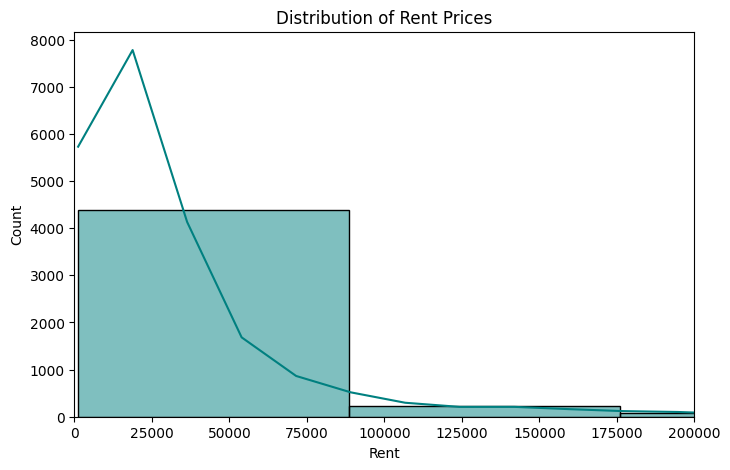

In [18]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Rent'], bins=40, kde=True, color='teal')
plt.title('Distribution of Rent Prices')
plt.xlabel('Rent')
plt.ylabel('Count')
plt.xlim(0, 200000)
plt.show()

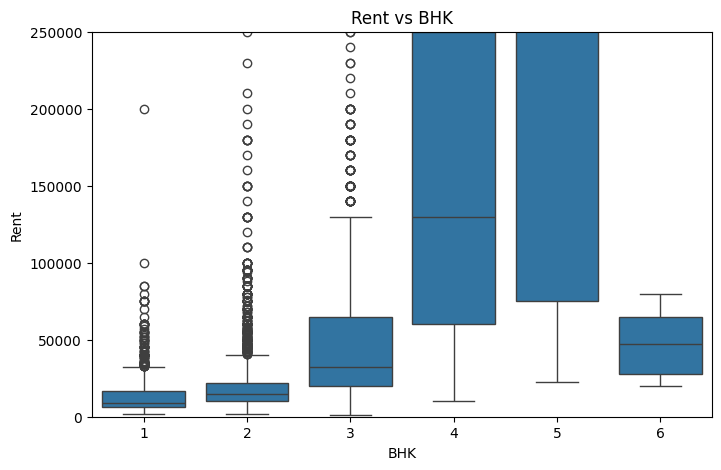

In [19]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='BHK', y='Rent', data=df)
plt.title('Rent vs BHK')
plt.xlabel('BHK')
plt.ylabel('Rent')
plt.ylim(0, 250000)
plt.show()

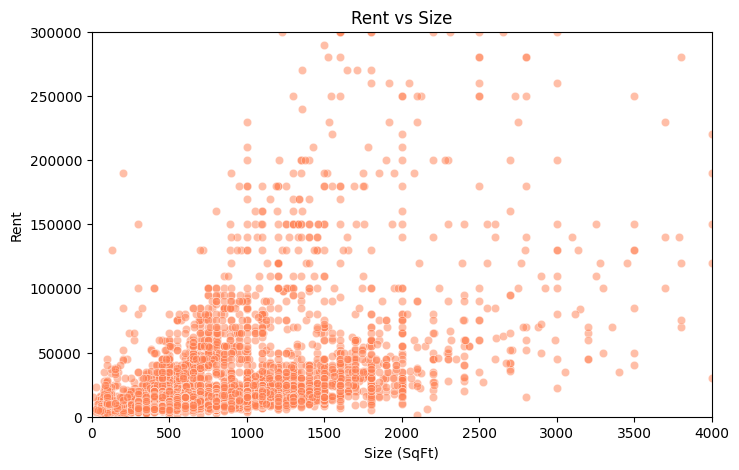

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Size', y='Rent', data=df, alpha=0.5, color='coral')
plt.title('Rent vs Size')
plt.xlabel('Size (SqFt)')
plt.ylabel('Rent')
plt.ylim(0, 300000)
plt.xlim(0, 4000)
plt.show()

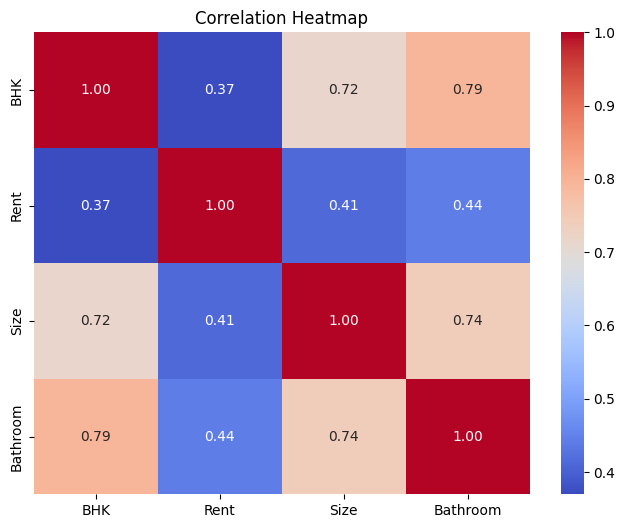

In [21]:
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [22]:
categorical_cols = ['Area Type', 'Furnishing Status', 'City', 'Tenant Preferred', 'Point of Contact']

df_encoded = pd.get_dummies(df, columns=['Area Type', 'Furnishing Status', 'City'], drop_first=True)

print("Shape before encoding:", df.shape)
print("Shape after encoding:", df_encoded.shape)
df_encoded.head(2)

Shape before encoding: (4746, 12)
Shape after encoding: (4746, 18)


,Posted On,BHK,Rent,Size,Floor,Area Locality,Tenant Preferred,Bathroom,Point of Contact,Area Type_Carpet Area,Area Type_Super Area,Furnishing Status_Semi-Furnished,Furnishing Status_Unfurnished,City_Chennai,City_Delhi,City_Hyderabad,City_Kolkata,City_Mumbai
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Bandel,Bachelors/Family,2.0,Contact Owner,False,True,False,True,False,False,False,True,False
1,5/13/2022,2,20000.0,850.0,1 out of 3,"Phool Bagan, Kankurgachi",Bachelors/Family,1.0,Contact Owner,False,True,True,False,False,False,False,True,False


In [23]:
X = df_encoded.drop(columns=['Rent', 'Posted On', 'Floor', 'Area Locality', 'Tenant Preferred', 'Point of Contact'], errors='ignore')
y = df_encoded['Rent']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4746, 12)
y shape: (4746,)


In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (3796, 12)
X_test shape: (950, 12)


In [25]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Mean of scaled X_train:", round(X_train_scaled.mean(), 5))
print("Std of scaled X_train:", round(X_train_scaled.std(), 5))

Mean of scaled X_train: 0.0
Std of scaled X_train: 1.0


In [26]:
from sklearn.linear_model import LinearRegression

In [27]:
model=LinearRegression(
    fit_intercept=True,
    copy_X=True,
    n_jobs=None,
    positive=False,
)

In [28]:
model.fit(X_train,y_train)

LinearRegression()

In [29]:
from  sklearn.metrics import mean_absolute_error , mean_squared_error,root_mean_squared_error,r2_score

In [30]:
y_pred = model.predict(X_test)

In [31]:
print("MAE : ",mean_absolute_error(y_test,y_pred))
print("MSE : ",mean_squared_error(y_test,y_pred))
print("RMSE : ",root_mean_squared_error(y_test,y_pred))
print("R2 : ",r2_score(y_test,y_pred))

MAE :  22281.11756075379
MSE :  1906015862.9831054
RMSE :  43657.941579775674
R2 :  0.5216840598176853


In [32]:
y_log = np.log1p(y)
X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.2, random_state=42)

model.fit(X_train, y_train)
y_pred = np.expm1(model.predict(X_test))
y_true = np.expm1(y_test)

print("R2:", r2_score(y_true, y_pred))
print("MAE:", mean_absolute_error(y_true, y_pred))

R2: 0.7602177160613504
MAE: 11606.897986385333


In [33]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [34]:
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

In [35]:
import time
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # لازم تتعمل بعد آخر train_test_split
X_test_scaled = scaler.transform(X_test)

models["SVM"] = SVR(kernel='rbf', C=10)

needs_scaling = {"SVM", "KNN"}
errors, times = {}, {}

for model_name, model in tqdm(models.items()):
    Xtr, Xte = (X_train_scaled, X_test_scaled) if model_name in needs_scaling else (X_train, X_test)

    start = time.time()
    model.fit(Xtr, y_train)
    times[model_name] = time.time() - start

    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, Xtr, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, Xte, y_test)

    errors[model_name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R_Train, "R2 Test": R_Test,
    }

pd.Series(times).sort_values(ascending=False)



 93%|█████████▎| 14/15 [00:12<00:00,  1.33it/s]

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001622 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 272
[LightGBM] [Info] Number of data points in the train set: 3796, number of used features: 12
[LightGBM] [Info] Start training from score 9.880175


100%|██████████| 15/15 [00:13<00:00,  1.14it/s]


,0
SVM,3.049638
ExtraTrees,1.368881
XGBoost,1.175867
Bagging,0.720291
Random Forest,0.625523
HistGradientBoosting,0.577484
GradientBoosting,0.534127
CatBoost,0.352165
LightGBM,0.209187
AdaBoost,0.115714


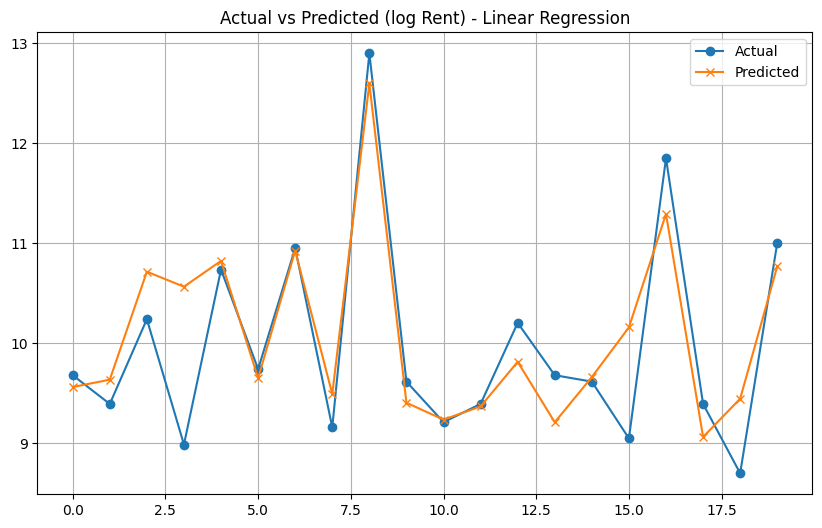

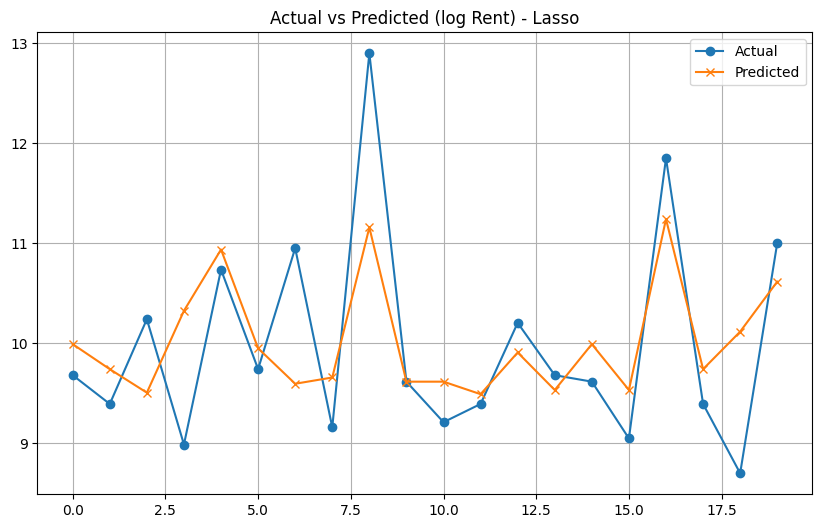

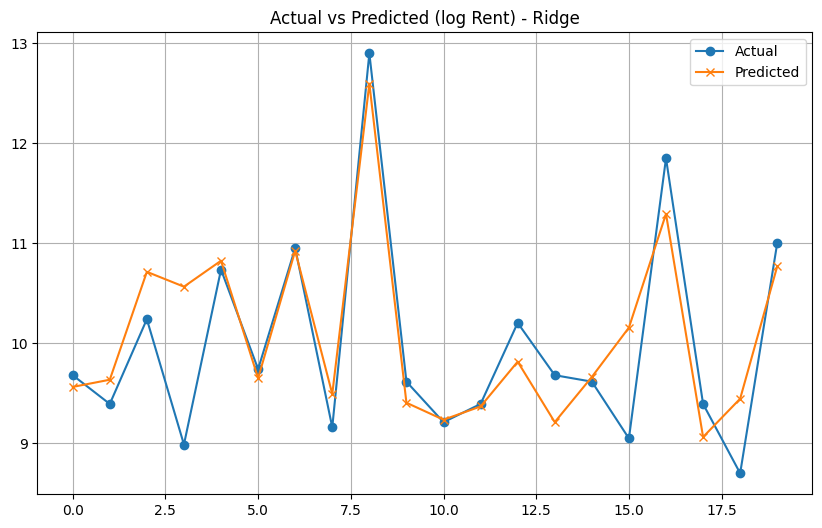

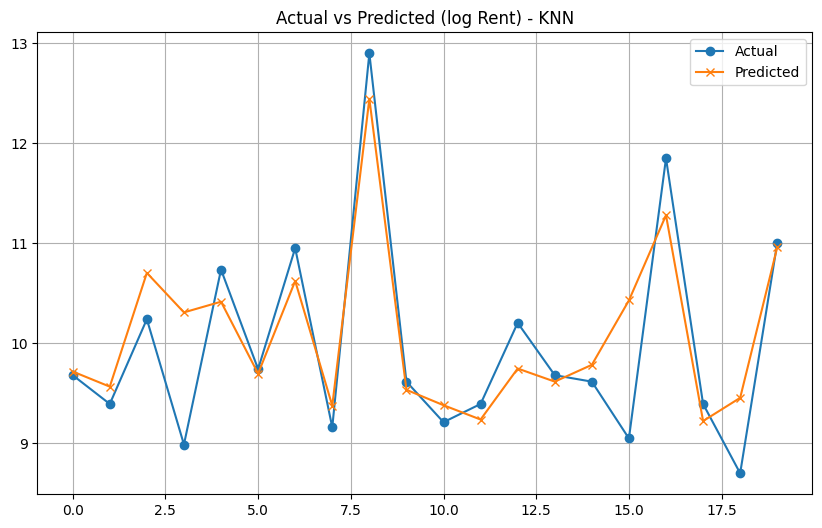

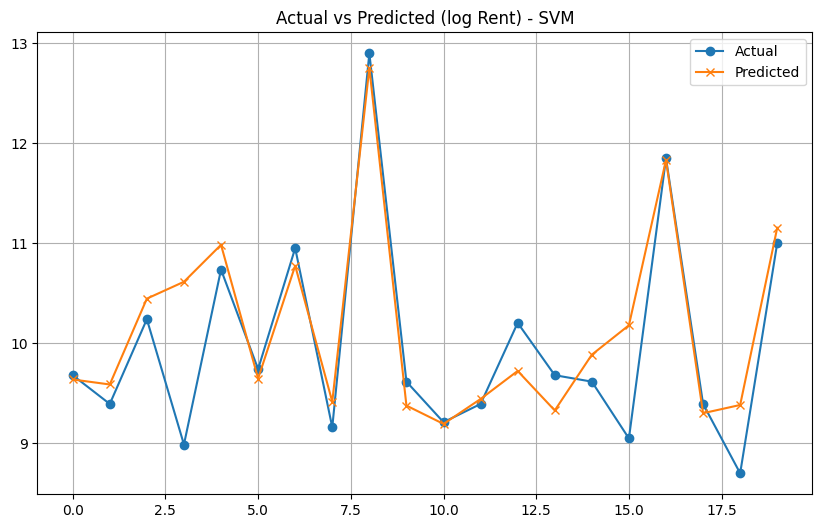

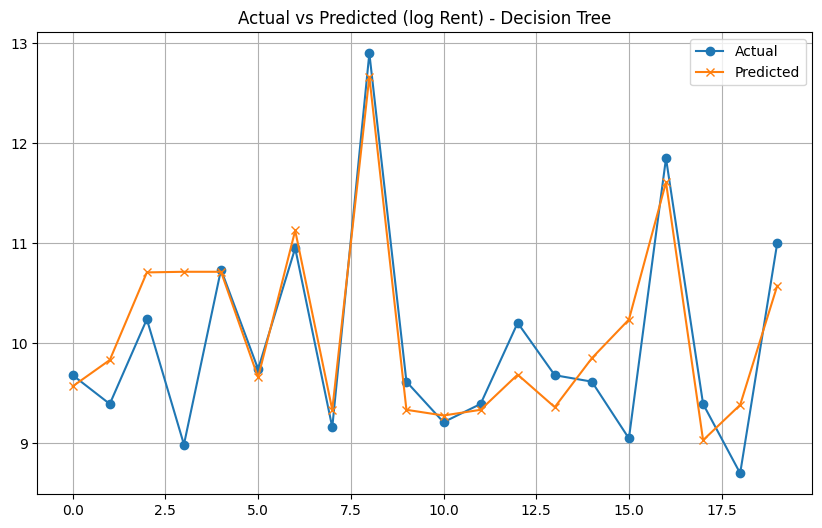

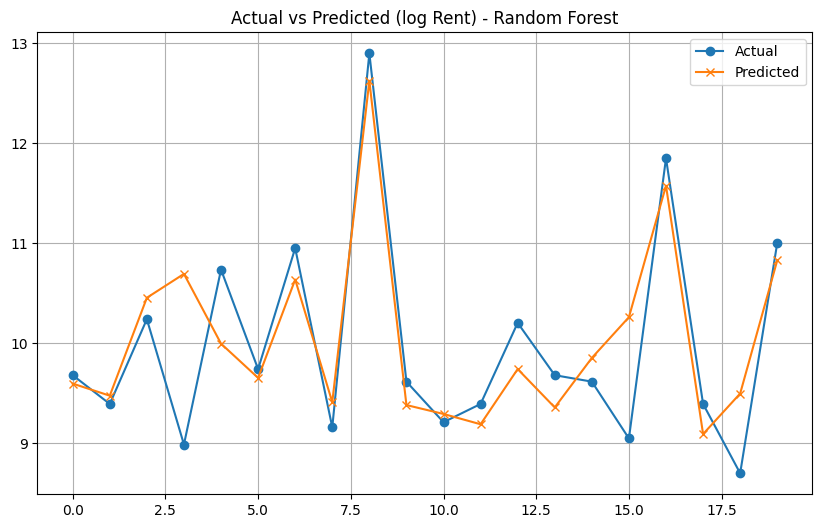

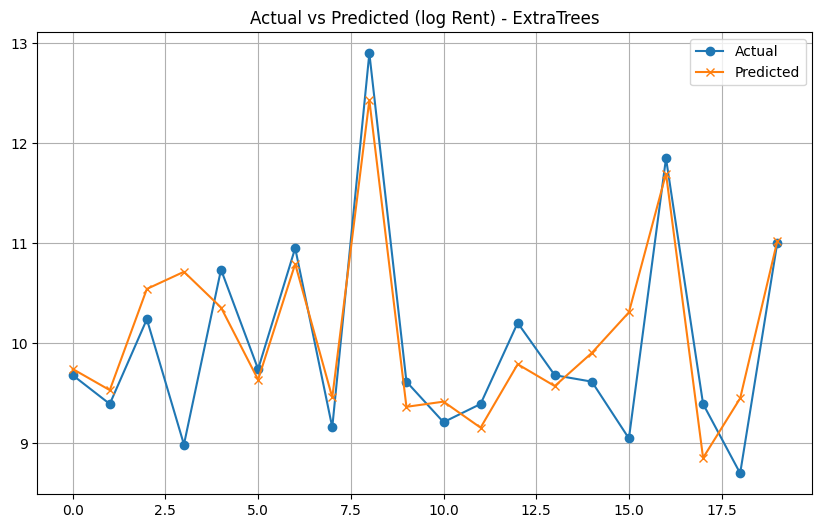

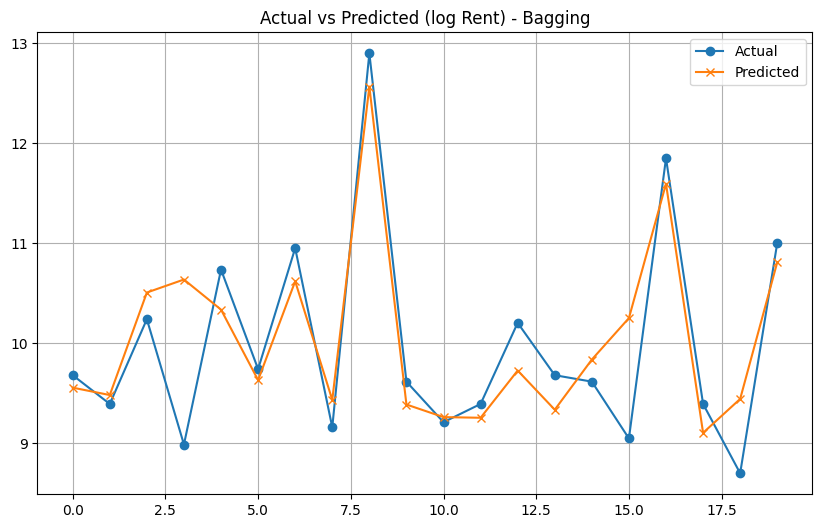

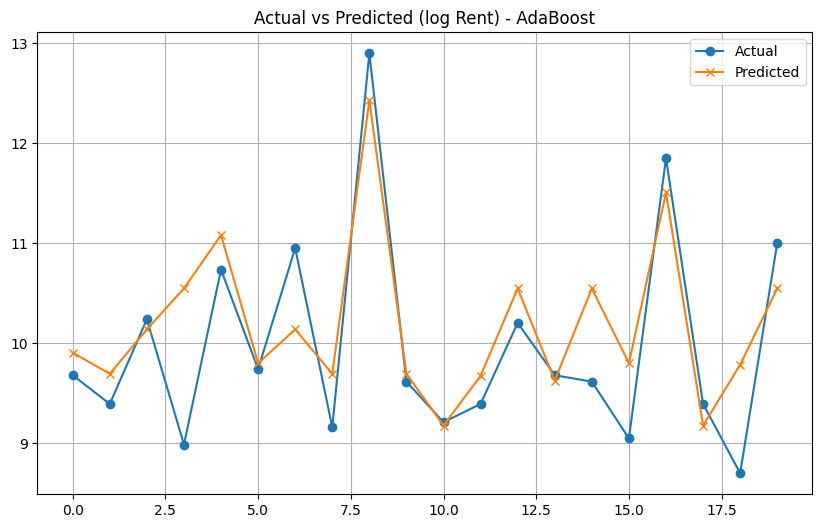

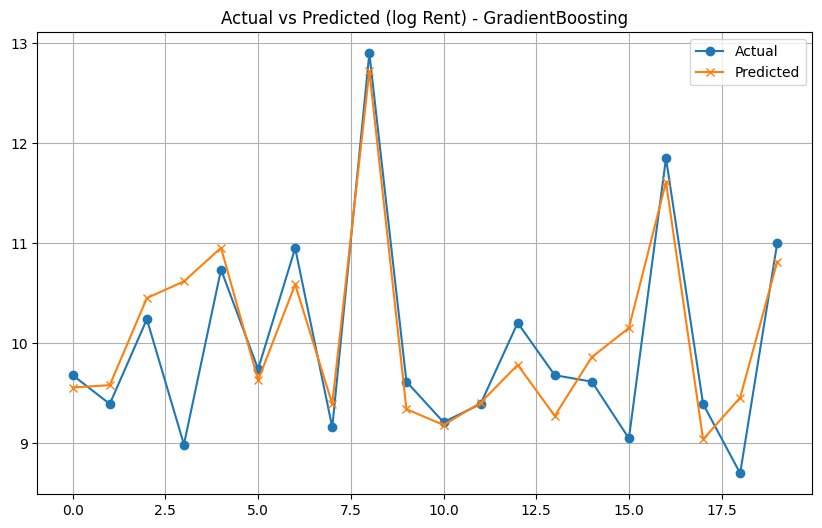

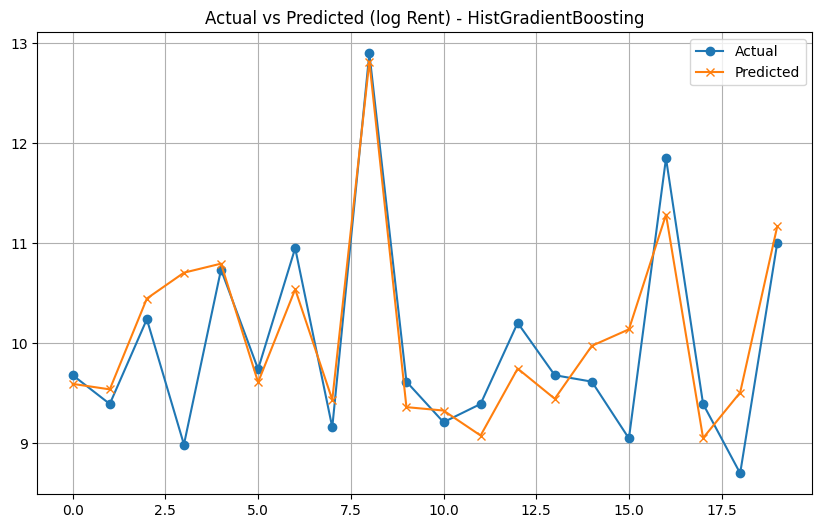

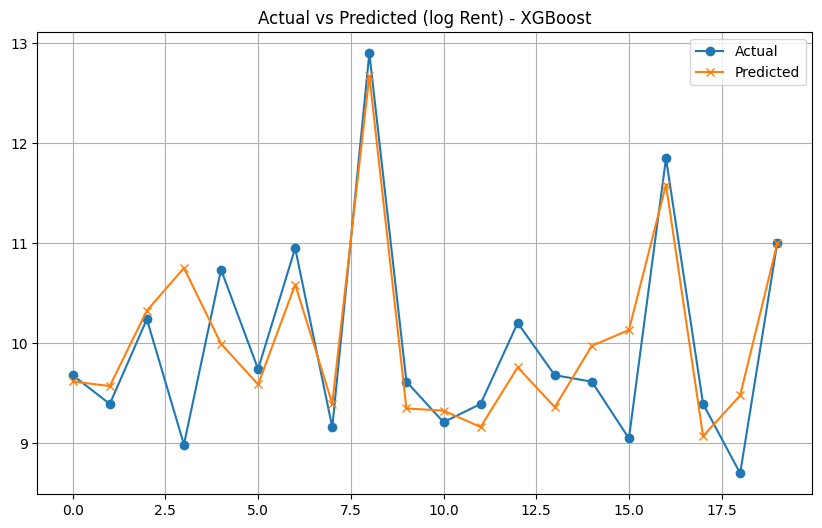

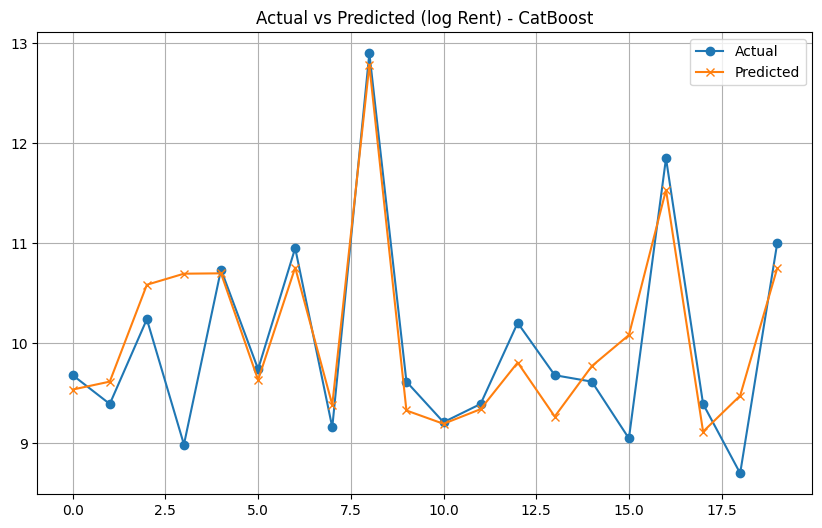

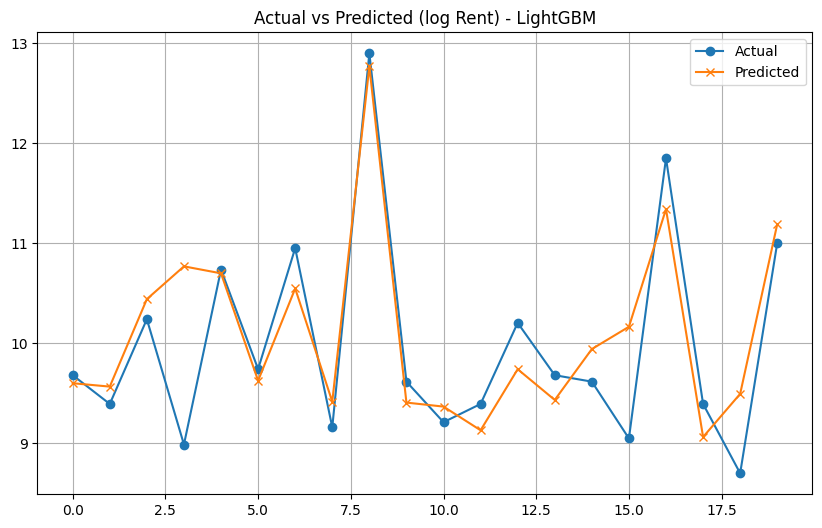

In [36]:
n = 20
for model_name, model in models.items():
    Xte = X_test_scaled if model_name in needs_scaling else X_test
    plt.figure(figsize=(10, 6))
    plt.plot(range(n), y_test.values[:n], label='Actual', marker='o')
    plt.plot(range(n), model.predict(Xte[:n]), label='Predicted', marker='x')
    plt.title('Actual vs Predicted (log Rent) - ' + model_name)
    plt.legend(); plt.grid()
    plt.show()

In [37]:
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1, n_jobs=-1)
clf3 = DecisionTreeRegressor(random_state=1)

voting = VotingRegressor(estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)])
weighted_voting = VotingRegressor(
    estimators=[('lr', clf1), ('rf', clf2), ('dt', clf3)], weights=[2, 1, 2]
)

def add_result(name, mdl):
    MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(mdl, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R2_Test = regression_metrics(mdl, X_test, y_test)
    errors[name] = {
        "MAE Train": MAE_Train, "MAE Test": MAE_Test,
        "MSE Train": MSE_Train, "MSE Test": MSE_Test,
        "RMSE Train": RMSE_Train, "RMSE Test": RMSE_Test,
        "R2 Train": R2_Train, "R2 Test": R2_Test,
    }

voting.fit(X_train, y_train)
add_result("Voting", voting)

weighted_voting.fit(X_train, y_train)
add_result("Weighted Voting", weighted_voting)

In [38]:
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [39]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [40]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
GradientBoosting,0.288080,0.304106,0.150162,0.153984,0.387508,0.392409,0.829266,0.821087
CatBoost,0.285613,0.303404,0.147338,0.154639,0.383846,0.393242,0.832478,0.820327
HistGradientBoosting,0.267726,0.307911,0.127161,0.157921,0.356596,0.397393,0.855419,0.816514
LightGBM,0.265651,0.308090,0.124775,0.158043,0.353235,0.397547,0.858131,0.816371
XGBoost,0.248136,0.308344,0.107261,0.160729,0.327508,0.400910,0.878044,0.813251
Bagging,0.235923,0.310796,0.095551,0.163594,0.309113,0.404468,0.891359,0.809922
Ridge,0.315113,0.310561,0.184800,0.165165,0.429884,0.406405,0.789883,0.808097
Linear Regression,0.315070,0.310577,0.184797,0.165192,0.429880,0.406439,0.789887,0.808065
Random Forest,0.236029,0.312324,0.095238,0.165303,0.308607,0.406575,0.891715,0.807937
SVM,0.269062,0.310816,0.141149,0.166383,0.375698,0.407901,0.839514,0.806681


<Axes: >

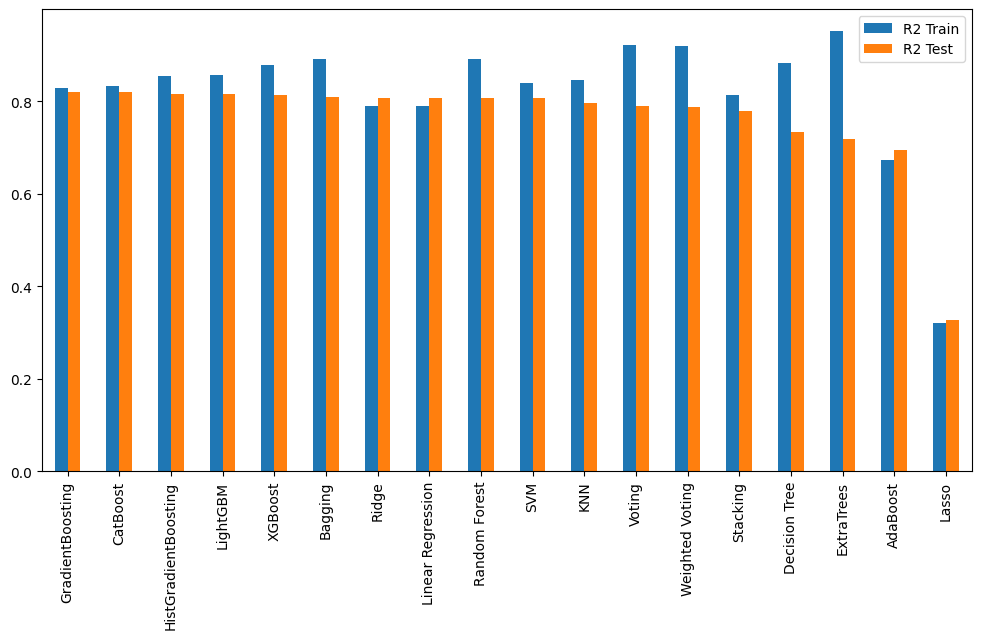

In [41]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

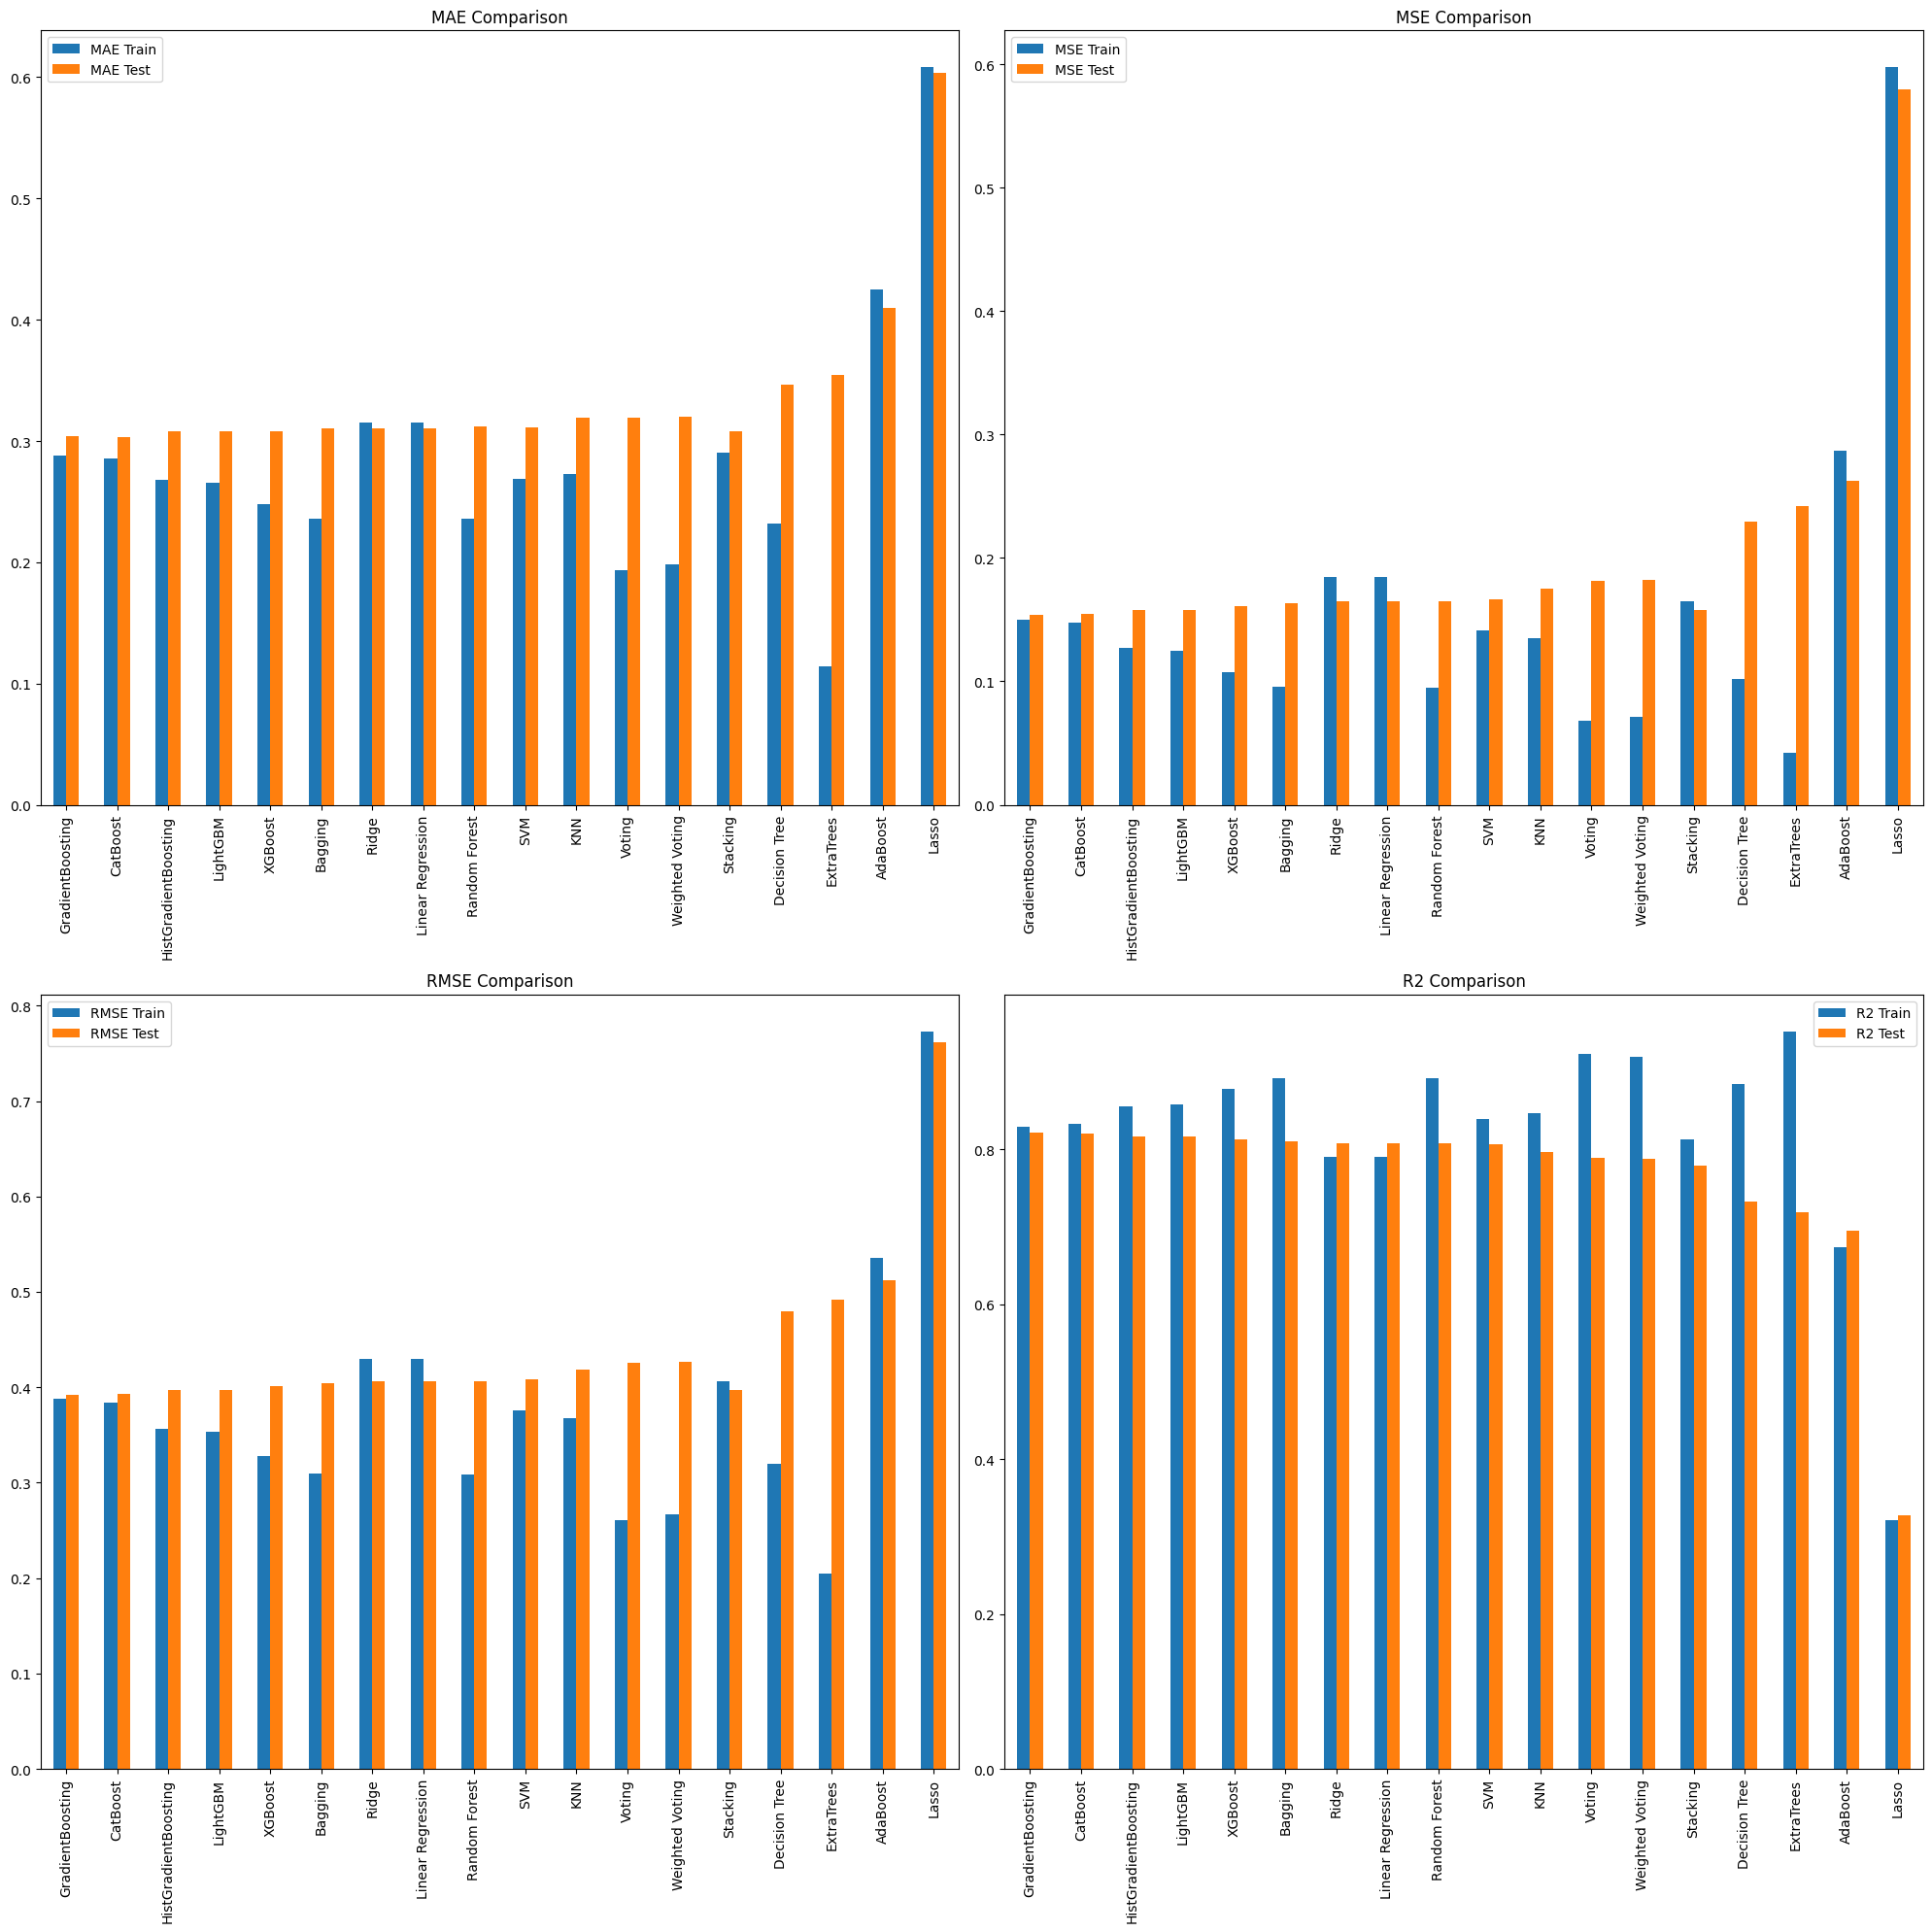

In [42]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()